Data Teks

In [1]:
import pandas as pd
from pathlib import Path
import re

data = pd.DataFrame({
    'teks': [
        'Saya adalah mahasiswa yang sedang belajar matematika di kampus. '
        'Setiap hari saya membaca buku, mengerjakan tugas, dan berdiskusi '
        'dengan teman. Saya tidak ingin menunda pekerjaan karena belajar '
        'dengan rajin dapat membantu saya meraih cita-cita. Setelah kuliah, '
        'saya biasanya makan nasi goreng dan beristirahat di rumah.'
    ],
    'label_asli': [0]
})

data['label'] = data['label_asli'].map({
    0: 'normal',
    1: 'spam',
    2: 'spam'
})

data.head()

,teks,label_asli,label
0,Saya adalah mahasiswa yang sedang belajar mate...,0,normal


1. Pemeriksaan Data

In [2]:
print('Ukuran data:', data.shape)
print('Nilai kosong:')
print(data.isna().sum())
print('Jumlah label:')
print(data['label'].value_counts())

Ukuran data: (1, 3)
Nilai kosong:
teks          0
label_asli    0
label         0
dtype: int64
Jumlah label:
label
normal    1
Name: count, dtype: int64


2. Case Folding dan Pembersihan Tanda Baca

In [3]:
data['huruf_kecil'] = data['teks'].str.lower()

data['bersih'] = data['huruf_kecil'].str.replace(
    r'[^a-z0-9\s]', ' ', regex=True
)

data['bersih'] = data['bersih'].str.replace(
    r'\s+', ' ', regex=True
).str.strip()

data[['teks', 'bersih']].head()

,teks,bersih
0,Saya adalah mahasiswa yang sedang belajar mate...,saya adalah mahasiswa yang sedang belajar mate...


3. Tokenisasi

In [4]:
contoh = data.loc[0, 'bersih']
token = contoh.split()
print('Teks bersih:', contoh)
print('Jumlah token:', len(token))
print('Token:', token)

Teks bersih: saya adalah mahasiswa yang sedang belajar matematika di kampus setiap hari saya membaca buku mengerjakan tugas dan berdiskusi dengan teman saya tidak ingin menunda pekerjaan karena belajar dengan rajin dapat membantu saya meraih cita cita setelah kuliah saya biasanya makan nasi goreng dan beristirahat di rumah
Jumlah token: 46
Token: ['saya', 'adalah', 'mahasiswa', 'yang', 'sedang', 'belajar', 'matematika', 'di', 'kampus', 'setiap', 'hari', 'saya', 'membaca', 'buku', 'mengerjakan', 'tugas', 'dan', 'berdiskusi', 'dengan', 'teman', 'saya', 'tidak', 'ingin', 'menunda', 'pekerjaan', 'karena', 'belajar', 'dengan', 'rajin', 'dapat', 'membantu', 'saya', 'meraih', 'cita', 'cita', 'setelah', 'kuliah', 'saya', 'biasanya', 'makan', 'nasi', 'goreng', 'dan', 'beristirahat', 'di', 'rumah']


4. Penghapusan Stopwords

In [6]:
%pip install Sastrawi

from Sastrawi.StopWordRemover.StopWordRemoverFactory import (
    StopWordRemoverFactory
)

stopwords = set(
    StopWordRemoverFactory().get_stop_words()
)

# Mempertahankan kata negasi
stopwords = stopwords - {
    'tidak', 'bukan', 'jangan', 'belum'
}

token_penting = [
    kata for kata in token
    if kata not in stopwords
]

print('Sebelum stopword removal:')
print(token)

print('\nSesudah stopword removal:')
print(token_penting)

Sebelum stopword removal:
['saya', 'adalah', 'mahasiswa', 'yang', 'sedang', 'belajar', 'matematika', 'di', 'kampus', 'setiap', 'hari', 'saya', 'membaca', 'buku', 'mengerjakan', 'tugas', 'dan', 'berdiskusi', 'dengan', 'teman', 'saya', 'tidak', 'ingin', 'menunda', 'pekerjaan', 'karena', 'belajar', 'dengan', 'rajin', 'dapat', 'membantu', 'saya', 'meraih', 'cita', 'cita', 'setelah', 'kuliah', 'saya', 'biasanya', 'makan', 'nasi', 'goreng', 'dan', 'beristirahat', 'di', 'rumah']

Sesudah stopword removal:
['mahasiswa', 'sedang', 'belajar', 'matematika', 'kampus', 'hari', 'membaca', 'buku', 'mengerjakan', 'tugas', 'berdiskusi', 'teman', 'tidak', 'menunda', 'pekerjaan', 'belajar', 'rajin', 'membantu', 'meraih', 'cita', 'cita', 'kuliah', 'biasanya', 'makan', 'nasi', 'goreng', 'beristirahat', 'rumah']


5. Stemming

In [7]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()

hasil_stem = [
    stemmer.stem(kata)
    for kata in token_penting
]

print('Sebelum stemming:')
print(token_penting)
print('\nSesudah stemming:')
print(hasil_stem)

Sebelum stemming:
['mahasiswa', 'sedang', 'belajar', 'matematika', 'kampus', 'hari', 'membaca', 'buku', 'mengerjakan', 'tugas', 'berdiskusi', 'teman', 'tidak', 'menunda', 'pekerjaan', 'belajar', 'rajin', 'membantu', 'meraih', 'cita', 'cita', 'kuliah', 'biasanya', 'makan', 'nasi', 'goreng', 'beristirahat', 'rumah']

Sesudah stemming:
['mahasiswa', 'sedang', 'ajar', 'matematika', 'kampus', 'hari', 'baca', 'buku', 'kerja', 'tugas', 'diskus', 'teman', 'tidak', 'tunda', 'kerja', 'ajar', 'rajin', 'bantu', 'raih', 'cita', 'cita', 'kuliah', 'biasa', 'makan', 'nasi', 'goreng', 'istirahat', 'rumah']


6. Frekuensi Kata

In [8]:
from collections import Counter

semua_kata = data['bersih'].str.split().explode()

frekuensi = Counter(
    kata for kata in semua_kata
    if kata not in stopwords
)

print('10 kata paling sering muncul:')
print(frekuensi.most_common(10))

10 kata paling sering muncul:
[('belajar', 2), ('cita', 2), ('mahasiswa', 1), ('sedang', 1), ('matematika', 1), ('kampus', 1), ('hari', 1), ('membaca', 1), ('buku', 1), ('mengerjakan', 1)]


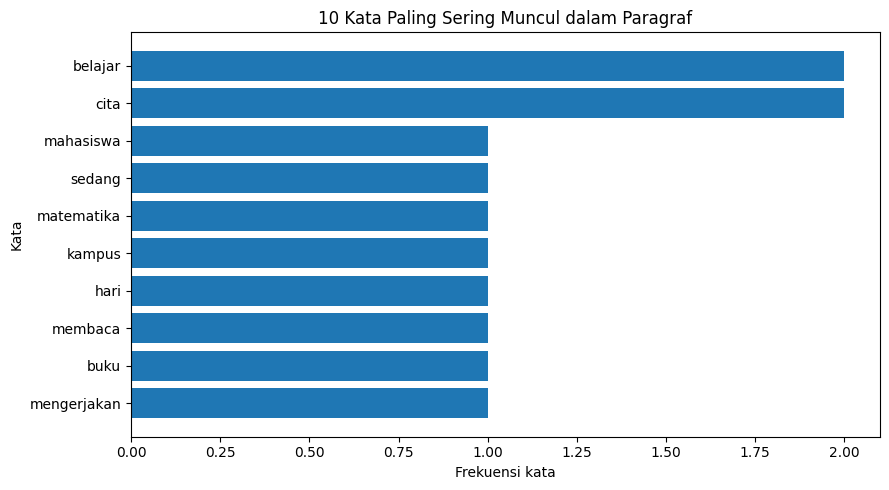

In [9]:
import matplotlib.pyplot as plt

kata_teratas = frekuensi.most_common(10)

kata = [item[0] for item in kata_teratas]
jumlah = [item[1] for item in kata_teratas]

plt.figure(figsize=(9, 5))
plt.barh(kata[::-1], jumlah[::-1])
plt.xlabel('Frekuensi kata')
plt.ylabel('Kata')
plt.title('10 Kata Paling Sering Muncul dalam Paragraf')
plt.tight_layout()
plt.show()

7. Bag of Words dengan CountVectorizer

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

dokumen = data['bersih']

count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

hasil_count = pd.DataFrame(
    matriks_count.toarray(),
    columns=count.get_feature_names_out()
)

print('Matriks CountVectorizer:')
print(hasil_count)

Matriks CountVectorizer:
   adalah  belajar  berdiskusi  beristirahat  biasanya  buku  cita  dan  \
0       1        2           1             1         1     1     2    2   

   dapat  dengan  ...  rajin  rumah  saya  sedang  setelah  setiap  teman  \
0      1       2  ...      1      1     5       1        1       1      1   

   tidak  tugas  yang  
0      1      1     1  

[1 rows x 37 columns]


8. TF-IDF

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

matriks_tfidf = tfidf.fit_transform(dokumen)

hasil_tfidf = pd.DataFrame(
    matriks_tfidf.toarray(),
    columns=tfidf.get_feature_names_out()
).round(3)

print('Matriks TF-IDF:')
print(hasil_tfidf)

Matriks TF-IDF:
   adalah  belajar  berdiskusi  beristirahat  biasanya   buku   cita    dan  \
0   0.115    0.229       0.115         0.115     0.115  0.115  0.229  0.229   

   dapat  dengan  ...  rajin  rumah   saya  sedang  setelah  setiap  teman  \
0  0.115   0.229  ...  0.115  0.115  0.574   0.115    0.115   0.115  0.115   

   tidak  tugas   yang  
0  0.115  0.115  0.115  

[1 rows x 37 columns]
